In [1]:
import sys
import numpy as np
import matplotlib.pyplot as plt
from urllib.request import Request, urlopen
from pathlib import Path

np.random.seed(14)
print("Python:", sys.version.split()[0])
print("NumPy :", np.__version__)
print("Perangkat: CPU / Google Colab sudah cukup")

Python: 3.13.16
NumPy : 2.1.3
Perangkat: CPU / Google Colab sudah cukup


In [2]:
def _samakan_bentuk_gradien(grad, bentuk_tujuan):
    """Jumlahkan sumbu hasil penyiaran (broadcasting) agar gradien cocok."""
    grad = np.asarray(grad, dtype=float)
    while grad.ndim > len(bentuk_tujuan):
        grad = grad.sum(axis=0)
    for sumbu, ukuran in enumerate(bentuk_tujuan):
        if ukuran == 1 and grad.shape[sumbu] != 1:
            grad = grad.sum(axis=sumbu, keepdims=True)
    return grad.reshape(bentuk_tujuan)

class Tensor:
    """Tensor NumPy dengan grafik gradien otomatis sederhana (untuk pembelajaran)."""

    def __init__(self, data, autograd=False, creators=None, creation_op=None):
        # Parameter yang perlu dilatih direpresentasikan dalam floating point.
        if isinstance(data, Tensor):
            data = data.data
        self.data = np.array(data, dtype=float if autograd else None)
        self.autograd = bool(autograd)
        self.creators = list(creators) if creators else []
        self.creation_op = creation_op
        self.grad = None
        self._backward = lambda: None

    def __repr__(self):
        return f"Tensor({self.data!r}, autograd={self.autograd})"

    def __str__(self):
        return str(self.data)

    def _tambah_grad(self, tambahan):
        if not self.autograd:
            return
        tambahan = np.asarray(tambahan, dtype=float)
        tambahan = _samakan_bentuk_gradien(tambahan, self.data.shape)
        if self.grad is None:
            self.grad = Tensor(tambahan)
        else:
            self.grad.data += tambahan

    @staticmethod
    def _tensor_lain(other):
        return other if isinstance(other, Tensor) else Tensor(other)

    def backward(self, grad=None):
        """Bangun urutan topologis, lalu alirkan gradien dari keluaran ke parameter."""
        if not self.autograd:
            raise ValueError("Tensor ini tidak mengaktifkan autograd.")
        if grad is None:
            grad = np.ones_like(self.data, dtype=float)
        elif isinstance(grad, Tensor):
            grad = grad.data
        grad = np.asarray(grad, dtype=float)
        if grad.shape != self.data.shape:
            raise ValueError("Bentuk gradien awal harus sama dengan bentuk keluaran.")

        urutan, dikunjungi = [], set()
        def kunjungi(node):
            if id(node) in dikunjungi:
                return
            dikunjungi.add(id(node))
            for induk in node.creators:
                if induk.autograd:
                    kunjungi(induk)
            urutan.append(node)
        kunjungi(self)

        # Bersihkan gradien simpul perantara; gradien parameter disimpan
        # sampai optimizer.step()/optimizer.zero() mengosongkannya.
        for node in urutan:
            if node.creators:
                node.grad = None
        self._tambah_grad(grad)
        for node in reversed(urutan):
            node._backward()

    def __add__(self, other):
        other = self._tensor_lain(other)
        out = Tensor(self.data + other.data,
                     self.autograd or other.autograd,
                     [self, other], "add")
        def turunan():
            self._tambah_grad(out.grad.data)
            other._tambah_grad(out.grad.data)
        out._backward = turunan
        return out

    def __radd__(self, other):
        return self + other

    def __neg__(self):
        out = Tensor(-self.data, self.autograd, [self], "neg")
        out._backward = lambda: self._tambah_grad(-out.grad.data)
        return out

    def __sub__(self, other):
        return self + (-self._tensor_lain(other))

    def __rsub__(self, other):
        return self._tensor_lain(other) - self

    def __mul__(self, other):
        other = self._tensor_lain(other)
        out = Tensor(self.data * other.data,
                     self.autograd or other.autograd,
                     [self, other], "mul")
        def turunan():
            self._tambah_grad(out.grad.data * other.data)
            other._tambah_grad(out.grad.data * self.data)
        out._backward = turunan
        return out

    def __rmul__(self, other):
        return self * other

    def sum(self, dim=None):
        out = Tensor(self.data.sum(axis=dim), self.autograd, [self], f"sum_{dim}")
        def turunan():
            g = out.grad.data
            if dim is not None:
                g = np.expand_dims(g, axis=dim)
            self._tambah_grad(np.broadcast_to(g, self.data.shape))
        out._backward = turunan
        return out

    def expand(self, dim, copies):
        nilai = np.repeat(np.expand_dims(self.data, dim), copies, axis=dim)
        out = Tensor(nilai, self.autograd, [self], f"expand_{dim}")
        out._backward = lambda: self._tambah_grad(out.grad.data.sum(axis=dim))
        return out

    def transpose(self):
        out = Tensor(self.data.T, self.autograd, [self], "transpose")
        out._backward = lambda: self._tambah_grad(out.grad.data.T)
        return out

    def mm(self, other):
        other = self._tensor_lain(other)
        if self.data.ndim != 2 or other.data.ndim != 2:
            raise ValueError("Operasi mm pada contoh ini menggunakan matriks 2D.")
        out = Tensor(self.data @ other.data,
                     self.autograd or other.autograd,
                     [self, other], "mm")
        def turunan():
            self._tambah_grad(out.grad.data @ other.data.T)
            other._tambah_grad(self.data.T @ out.grad.data)
        out._backward = turunan
        return out

    def sigmoid(self):
        z = np.clip(self.data, -500, 500)
        hasil = 1 / (1 + np.exp(-z))
        out = Tensor(hasil, self.autograd, [self], "sigmoid")
        out._backward = lambda: self._tambah_grad(out.grad.data * hasil * (1 - hasil))
        return out

    def tanh(self):
        hasil = np.tanh(self.data)
        out = Tensor(hasil, self.autograd, [self], "tanh")
        out._backward = lambda: self._tambah_grad(out.grad.data * (1 - hasil**2))
        return out

    def relu(self):
        hasil = np.maximum(0, self.data)
        out = Tensor(hasil, self.autograd, [self], "relu")
        out._backward = lambda: self._tambah_grad(out.grad.data * (self.data > 0))
        return out

    def index_select(self, indices):
        indices = self._tensor_lain(indices)
        posisi = np.asarray(indices.data, dtype=int)
        if not np.array_equal(posisi, indices.data):
            raise ValueError("Indeks harus bilangan bulat.")
        out = Tensor(self.data[posisi], self.autograd, [self], "index_select")
        def turunan():
            g = np.zeros_like(self.data, dtype=float)
            np.add.at(g, posisi, out.grad.data)  # Indeks berulang tetap terakumulasi
            self._tambah_grad(g)
        out._backward = turunan
        return out

    def cross_entropy(self, target_indices):
        """Entropi silang klasifikasi 2D; target berisi indeks kelas benar."""
        target = self._tensor_lain(target_indices)
        if self.data.ndim != 2:
            raise ValueError("Logit harus berbentuk (jumlah_data, jumlah_kelas).")
        label = np.asarray(target.data).reshape(-1).astype(int)
        if len(label) != self.data.shape[0]:
            raise ValueError("Jumlah label harus sesuai dengan jumlah data.")
        if label.min() < 0 or label.max() >= self.data.shape[1]:
            raise ValueError("Ada label di luar rentang kelas.")
        logit_aman = self.data - self.data.max(axis=1, keepdims=True)
        eks = np.exp(logit_aman)
        peluang = eks / eks.sum(axis=1, keepdims=True)
        n = len(label)
        rugi = -np.log(np.maximum(peluang[np.arange(n), label], 1e-300)).mean()
        out = Tensor(rugi, self.autograd, [self], "cross_entropy")
        def turunan():
            g = peluang.copy()
            g[np.arange(n), label] -= 1
            g = g / n  # konsisten dengan loss rata-rata (mean)
            self._tambah_grad(out.grad.data * g)
        out._backward = turunan
        return out

print("Tensor dan autograd siap digunakan.")

Tensor dan autograd siap digunakan.


### 2.1 Tes kecil: gradien dari jalur yang dipakai dua kali

Jika `y = x * x`, maka turunan `y` terhadap `x` adalah `2x`. Karena bobot dapat digunakan berulang sepanjang waktu, penjumlahan kontribusi gradien sangat penting untuk RNN dan LSTM.

In [3]:
x_uji = Tensor([2.0, 3.0], autograd=True)
y_uji = (x_uji * x_uji).sum()
y_uji.backward()
print("Nilai fungsi:", y_uji.data)
print("Gradien analitik:", x_uji.grad.data)
print("Gradien seharusnya:", 2 * x_uji.data)
assert np.allclose(x_uji.grad.data, [4., 6.])

Nilai fungsi: 13.0
Gradien analitik: [4. 6.]
Gradien seharusnya: [4. 6.]


## 3. Data Shakespeare dan pemodelan karakter

Berbeda dari Bab 12–13 (prediksi kata), **pemodelan bahasa karakter** memprediksi satu karakter berikutnya dari riwayat karakter sebelumnya. Contoh: `"Sa" → "y"` jika bagian data memuat `"Say"`.

Buku membaca berkas `shakespear.txt` yang berisi karya Shakespeare. Notebook mencoba memakai:

1. Berkas lokal `shakespear.txt` atau `shakespeare.txt` jika sudah tersedia.
2. `tinyshakespeare/input.txt` dari repositori publik `karpathy/char-rnn` (butuh internet; bukan berkas persis yang dipakai pada cetakan buku).
3. Jika keduanya tidak tersedia, **korpus mini Shakespeare** yang disertakan sebagai cadangan untuk demonstrasi, bukan substitusi dataset asli.

**Perhatian:** hasil cadangan hanyalah simulasi praktik, sehingga skor dan kualitas sampel tidak boleh ditafsirkan sebagai hasil pelatihan pada seluruh Shakespeare.

In [4]:
SUMBER_TINY_SHAKESPEARE = "https://raw.githubusercontent.com/karpathy/char-rnn/master/data/tinyshakespeare/input.txt"
contoh_publik = """ROMEO:
But, soft! what light through yonder window breaks?
It is the east, and Juliet is the sun.
Arise, fair sun, and kill the envious moon.

JULIET:
O Romeo, Romeo! wherefore art thou Romeo?
Deny thy father and refuse thy name.
What's in a name? That which we call a rose
By any other name would smell as sweet.

HAMLET:
To be, or not to be, that is the question:
Whether 'tis nobler in the mind to suffer
The slings and arrows of outrageous fortune,
Or to take arms against a sea of troubles.

MACBETH:
Tomorrow, and tomorrow, and tomorrow,
Creeps in this petty pace from day to day.

SONNET:
Shall I compare thee to a summer's day?
Thou art more lovely and more temperate.
Rough winds do shake the darling buds of May.
"""

def ambil_teks_shakespeare():
    for nama in ("shakespear.txt", "shakespeare.txt", "input.txt"):
        path = Path(nama)
        if path.exists():
            isi = path.read_text(encoding="utf-8", errors="replace")
            if len(isi) > 200:
                return isi, f"Berkas lokal: {nama}"
    try:
        permintaan = Request(SUMBER_TINY_SHAKESPEARE, headers={"User-Agent": "Mozilla/5.0"})
        with urlopen(permintaan, timeout=12) as sambungan:
            isi = sambungan.read().decode("utf-8", errors="replace")
        if len(isi) < 1000:
            raise ValueError("Isi hasil unduhan terlalu pendek")
        return isi, f"Unduhan: {SUMBER_TINY_SHAKESPEARE}"
    except Exception as galat:
        print("Unduhan tidak tersedia:", str(galat)[:110])
        return contoh_publik * 18, "CADANGAN: cuplikan sastra yang diulang untuk demonstrasi"

raw, sumber_aktif = ambil_teks_shakespeare()
MAKS_KARAKTER = 24000  # versi cepat. Bisa dinaikkan jika ingin eksperimen lebih besar.
raw = raw[:MAKS_KARAKTER]
print("Sumber:", sumber_aktif)
print("Banyak karakter:", len(raw))
print("Cuplikan awal:\n", repr(raw[:200]))
assert len(raw) > 1000

Sumber: Unduhan: https://raw.githubusercontent.com/karpathy/char-rnn/master/data/tinyshakespeare/input.txt
Banyak karakter: 24000
Cuplikan awal:
 'First Citizen:\nBefore we proceed any further, hear me speak.\n\nAll:\nSpeak, speak.\n\nFirst Citizen:\nYou are all resolved rather to die than to famish?\n\nAll:\nResolved. resolved.\n\nFirst Citizen:\nFirst, you'


## 4. Membuat kosakata karakter dan representasi numerik

Setiap karakter unik (huruf, spasi, tanda baca, `\n`) memperoleh indeks bilangan bulat. Dalam model, indeks ini dipetakan ke vektor embedding melalui tabel bobot yang dipelajari.

**Bentuk data:** `indices` berdimensi `(panjang_teks,)` dan kosakata berdimensi `V = jumlah_karakter_unik`. Keluaran jaringan untuk setiap karakter memiliki `V` logit: satu nilai untuk setiap karakter yang mungkin muncul berikutnya.

In [5]:
vocab = sorted(set(raw))  # urutan dibuat tetap agar hasil konsisten
char2index = {karakter: i for i, karakter in enumerate(vocab)}
index2char = {i: karakter for karakter, i in char2index.items()}
indices = np.asarray([char2index[karakter] for karakter in raw], dtype=np.int64)
print("Banyak karakter unik:", len(vocab))
print("Lima karakter awal:", list(raw[:5]))
print("Lima indeks awal:", indices[:5])
print("Bentuk indices:", indices.shape)
assert ''.join(index2char[int(i)] for i in indices[:40]) == raw[:40]

Banyak karakter unik: 58
Lima karakter awal: ['F', 'i', 'r', 's', 't']
Lima indeks awal: [15 40 49 50 51]
Bentuk indices: (24000,)


## 5. Mengapa membutuhkan *truncated backpropagation through time* (TBPTT)?

RNN menghitung status tersembunyi pada waktu ke-`t` menggunakan status pada waktu sebelumnya. Bila satu buku penuh dianggap satu sekuens panjang, grafik *backpropagation* menjadi sangat besar dan mahal di memori.

Solusi buku: menjalankan propagasi maju sepanjang **`bptt` langkah**, menghitung gradien hanya dalam potongan tersebut, memperbarui bobot, lalu melanjutkan dengan nilai status tersembunyi terakhir **tanpa riwayat gradien dari potongan sebelumnya**.

- Status (informasi numerik) bisa diteruskan lintas potongan.
- Jalur gradien diputus pada batas potongan (*detach*).
- Akibatnya, pembelajaran dependensi sangat jauh lebih sulit, meskipun informasi lama masih mungkin terbawa dalam status.

Jika `batch_size=8`, data dibagi menjadi delapan aliran berkesinambungan. Setiap potongan memuat `bptt` langkah dari masing-masing aliran.

In [6]:
def buat_batch_tbptt(deret_indeks, batch_size=8, bptt=16):
    if len(deret_indeks) < batch_size * (bptt + 1):
        raise ValueError("Korpus terlalu pendek untuk parameter batch yang dipilih.")
    jumlah_per_aliran = len(deret_indeks) // batch_size
    dipangkas = deret_indeks[:jumlah_per_aliran * batch_size]
    aliran = dipangkas.reshape(batch_size, jumlah_per_aliran).T
    masukan, target = aliran[:-1], aliran[1:]
    n_potongan = len(masukan) // bptt
    masukan = masukan[:n_potongan * bptt].reshape(n_potongan, bptt, batch_size)
    target = target[:n_potongan * bptt].reshape(n_potongan, bptt, batch_size)
    return masukan, target

BATCH_SIZE = 8
BPTT = 16
input_batches, target_batches = buat_batch_tbptt(indices, BATCH_SIZE, BPTT)
print("Bentuk input:", input_batches.shape, "(potongan, waktu, kelompok)")
print("Bentuk target:", target_batches.shape)
print("Contoh input aliran pertama:", ''.join(index2char[int(i)] for i in input_batches[0,:,0]))
print("Contoh target aliran pertama:", ''.join(index2char[int(i)] for i in target_batches[0,:,0]))
assert np.array_equal(input_batches[0,1:,0], target_batches[0,:-1,0])
assert input_batches.shape == target_batches.shape

Bentuk input: (187, 16, 8) (potongan, waktu, kelompok)
Bentuk target: (187, 16, 8)
Contoh input aliran pertama: First Citizen:
B
Contoh target aliran pertama: irst Citizen:
Be


### 5.1 Pemeriksaan pergeseran satu karakter

Setiap keluaran di waktu `t` bertugas memprediksi karakter `t+1` pada aliran yang sama. Batch `n` dan batch `n+1` berurutan sepanjang masing-masing aliran, **bukan** pencampuran acak karakter dalam satu potongan.

In [7]:
tampilan_input = ''.join(index2char[int(i)] for i in input_batches[0, :12, 0])
tampilan_target = ''.join(index2char[int(i)] for i in target_batches[0, :12, 0])
print("Masukan  :", repr(tampilan_input))
print("Target   :", repr(tampilan_target))
print("Cocok bergeser satu posisi:", tampilan_input[1:] == tampilan_target[:-1])
assert tampilan_input[1:] == tampilan_target[:-1]

Masukan  : 'First Citize'
Target   : 'irst Citizen'
Cocok bergeser satu posisi: True


## 6. Mengamati *vanishing gradient* dan *exploding gradient*

Bab 14 memberikan percobaan sederhana memakai matriks berulang

\[W=\begin{bmatrix}1&4\\4&1\end{bmatrix}.\]

Saat propagasi balik, komponen gradien berulang kali dikalikan dengan turunan aktivasi dan matriks bobot. Turunan sigmoid yang kecil (dekat 0 atau 1) cenderung menyusutkan gradien, sedangkan perkalian matriks dengan faktor penguatan tinggi dapat membesarkannya.

**Penting:** LSTM mengurangi masalah gradien sepanjang jalur *cell state*, tetapi **tidak menjamin** gradien bebas dari masalah tersebut pada semua parameter, data, dan konfigurasi.

Norma gradien sigmoid pada langkah terakhir: 2.61e-14
Norma gradien ReLU pada langkah terakhir   : 1.38e+07


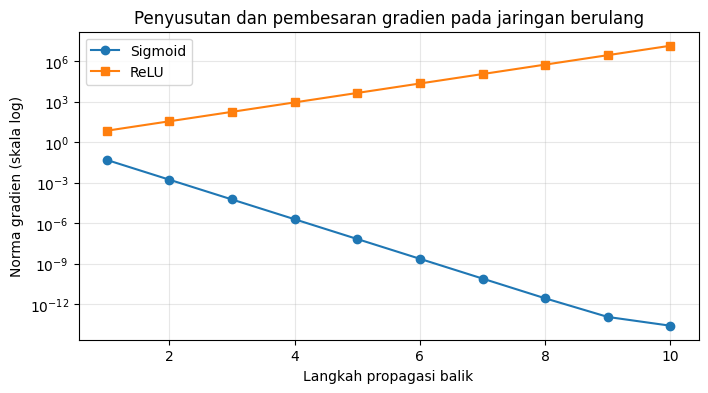

In [8]:
def sigmoid_numpy(x):
    return 1.0 / (1.0 + np.exp(-np.clip(x, -100, 100)))

def percobaan_gradien(aktivasi="sigmoid", langkah=10):
    W = np.array([[1., 4.], [4., 1.]])
    a = sigmoid_numpy(np.array([1., 0.01]))
    status = []
    for _ in range(langkah):
        z = a @ W
        a = sigmoid_numpy(z) if aktivasi == "sigmoid" else np.maximum(z, 0.0)
        status.append(a.copy())
    g = np.ones_like(a)
    norma = []
    for a in status[::-1]:
        turunan = a * (1-a) if aktivasi == "sigmoid" else (a > 0).astype(float)
        g = (g * turunan) @ W.T
        norma.append(float(np.linalg.norm(g)))
    return np.array(norma), np.array(status)

norma_sigmoid, status_sigmoid = percobaan_gradien("sigmoid")
norma_relu, status_relu = percobaan_gradien("relu")
print("Norma gradien sigmoid pada langkah terakhir:", f"{norma_sigmoid[-1]:.2e}")
print("Norma gradien ReLU pada langkah terakhir   :", f"{norma_relu[-1]:.2e}")
plt.figure(figsize=(8,4))
plt.semilogy(range(1,11), norma_sigmoid, marker="o", label="Sigmoid")
plt.semilogy(range(1,11), norma_relu, marker="s", label="ReLU")
plt.xlabel("Langkah propagasi balik")
plt.ylabel("Norma gradien (skala log)")
plt.title("Penyusutan dan pembesaran gradien pada jaringan berulang")
plt.legend(); plt.grid(alpha=.3); plt.show()
assert norma_sigmoid[-1] < norma_sigmoid[0]
assert norma_relu[-1] > norma_relu[0]

## 7. Konsep LSTM dan empat jenis gerbang

Pada RNN biasa, status tersembunyi melalui transformasi matriks dan nonlinearitas di setiap waktu. LSTM menambahkan *cell state* `c`, jalur yang dapat mempertahankan informasi melalui perkalian gerbang dan penjumlahan.

Untuk masukan `xₜ`, status tersembunyi sebelumnya `hₜ₋₁`, dan memori sebelumnya `cₜ₋₁`:

\[
\begin{aligned}
f_t &= \sigma(W_{xf} x_t + W_{hf} h_{t-1}+b_f) &&\text{gerbang lupa}\\
i_t &= \sigma(W_{xi} x_t + W_{hi} h_{t-1}+b_i) &&\text{gerbang masukan}\\
o_t &= \sigma(W_{xo} x_t + W_{ho} h_{t-1}+b_o) &&\text{gerbang keluaran}\\
u_t &= \tanh(W_{xc} x_t+W_{hc} h_{t-1}+b_u) &&\text{calon informasi baru}\\
c_t &= f_t \odot c_{t-1}+i_t\odot u_t\\
h_t &= o_t\odot \tanh(c_t).
\end{aligned}
\]

Simbol `⊙` menunjukkan perkalian elemen demi elemen. Buku memakai nama `u` atau `g` untuk calon pembaruan. **Peran masing-masing:**

- **Lupa (f):** memilih informasi lama mana yang dipertahankan.
- **Masukan (i):** mengatur seberapa besar calon informasi baru ditulis.
- **Keluaran (o):** memilih informasi memori mana yang terlihat di `h`.
- **Calon pembaruan (u):** informasi baru yang berpotensi ditambahkan.

Jika `f` mendekati 1 dan `i` mendekati 0, nilai memori lebih mudah bertahan. Inilah inti konsep *gated copy* pada buku.

### 7.1 Percobaan gerbang tanpa pelatihan

Sebelum menulis kelas LSTM, coba periksa dua kondisi sederhana yang memperlihatkan bagaimana nilai `c` diperbarui. Contoh ini ilustratif, bukan hasil belajar jaringan.

In [9]:
memori_lama = np.array([0.8, -0.3])
calon = np.array([0.9, 0.5])
pertahankan = (np.ones(2)*0.99)*memori_lama + (np.ones(2)*0.01)*calon
lupakan = (np.ones(2)*0.01)*memori_lama + (np.ones(2)*0.99)*calon
print("Memori sebelumnya:", memori_lama)
print("Saat gerbang lupa tinggi, masukan rendah:", pertahankan)
print("Saat gerbang lupa rendah, masukan tinggi:", lupakan)
assert np.linalg.norm(pertahankan - memori_lama) < np.linalg.norm(lupakan - memori_lama)

Memori sebelumnya: [ 0.8 -0.3]
Saat gerbang lupa tinggi, masukan rendah: [ 0.801 -0.292]
Saat gerbang lupa rendah, masukan tinggi: [0.899 0.492]


## 8. Menyiapkan *layer* dan pengoptimal (mengikuti Bab 13)

Sesuai alur buku, kita membuat `Layer`, `Linear`, `Embedding`, `CrossEntropyLoss`, `RNNCell`, dan `SGD`. `Linear` menghitung pemetaan matriks dan bias; `Embedding` mengambil vektor karakter; `CrossEntropyLoss` membandingkan logit karakter dengan indeks target.

**Penyesuaian dari buku:** `CrossEntropyLoss` di sini merata-ratakan rugi **per karakter di dalam satu batch**, kemudian selama satu potongan `bptt` dilakukan rerata lagi. Dengan demikian skala rugi tetap stabil saat ukuran batch dan panjang potongan berubah.

In [10]:
class SGD:
    def __init__(self, parameters, alpha=0.1):
        # Hilangkan parameter kembar bila suatu bobot dipakai beberapa tempat.
        self.parameters = list({id(p): p for p in parameters}.values())
        self.alpha = float(alpha)

    def zero(self):
        for p in self.parameters:
            p.grad = None

    def step(self, zero=True):
        for p in self.parameters:
            if p.grad is not None:
                p.data -= self.alpha * p.grad.data
        if zero:
            self.zero()

print("Kelas SGD siap digunakan.")

Kelas SGD siap digunakan.


In [11]:
class Layer:
    def get_parameters(self):
        return []
    def forward(self, *args):
        raise NotImplementedError

class Linear(Layer):
    def __init__(self, n_inputs, n_outputs, bias=True):
        self.weight = Tensor(np.random.randn(n_inputs, n_outputs) * np.sqrt(1.0/n_inputs), autograd=True)
        self.bias = Tensor(np.zeros(n_outputs), autograd=True) if bias else None
    def forward(self, input):
        hasil = input.mm(self.weight)
        return hasil + self.bias if self.bias is not None else hasil
    def get_parameters(self):
        return [self.weight] + ([self.bias] if self.bias is not None else [])

class Embedding(Layer):
    def __init__(self, vocab_size, dim):
        self.weight = Tensor((np.random.rand(vocab_size, dim)-0.5) * 0.1, autograd=True)
    def forward(self, input):
        return self.weight.index_select(input)
    def get_parameters(self):
        return [self.weight]

class CrossEntropyLoss(Layer):
    def forward(self, logits, target):
        return logits.cross_entropy(target)

class RNNCell(Layer):
    def __init__(self, n_inputs, n_hidden, n_output):
        self.n_hidden = n_hidden
        self.xh = Linear(n_inputs, n_hidden)
        self.hh = Linear(n_hidden, n_hidden, bias=False)
        self.ho = Linear(n_hidden, n_output)
    def forward(self, input, hidden):
        h = (self.xh.forward(input) + self.hh.forward(hidden)).tanh()
        output = self.ho.forward(h)
        return output, h
    def init_hidden(self, batch_size=1):
        return Tensor(np.zeros((batch_size, self.n_hidden)))
    def get_parameters(self):
        return self.xh.get_parameters()+self.hh.get_parameters()+self.ho.get_parameters()

print("Layer, Linear, Embedding, CrossEntropyLoss, dan RNNCell siap.")

Layer, Linear, Embedding, CrossEntropyLoss, dan RNNCell siap.


## 9. Implementasi `LSTMCell` dari nol

Kelas di bawah mengikuti struktur buku: empat pemetaan dari input (`xf`, `xi`, `xo`, `xc`), empat pemetaan dari status sebelumnya (`hf`, `hi`, `ho`, `hc`), dan satu proyeksi ke kosakata (`w_ho`).

Masukan kelas: vektor embedding saat ini dan pasangan `(h, c)` dari langkah sebelumnya. Keluaran kelas: logit untuk karakter selanjutnya dan pasangan `(h_baru, c_baru)`.

**Penting:** `init_hidden` mengembalikan **dua** tensor, bukan satu seperti pada RNN. Nilai awal default nol; buku memberi nilai 1 pada elemen pertama `h` dan `c`, yang akan ditunjukkan sebagai pilihan opsional di kelas.

In [12]:
class LSTMCell(Layer):
    def __init__(self, n_inputs, n_hidden, n_output):
        self.n_hidden = n_hidden
        self.xf = Linear(n_inputs, n_hidden)
        self.xi = Linear(n_inputs, n_hidden)
        self.xo = Linear(n_inputs, n_hidden)
        self.xc = Linear(n_inputs, n_hidden)
        self.hf = Linear(n_hidden, n_hidden, bias=False)
        self.hi = Linear(n_hidden, n_hidden, bias=False)
        self.ho = Linear(n_hidden, n_hidden, bias=False)
        self.hc = Linear(n_hidden, n_hidden, bias=False)
        self.w_ho = Linear(n_hidden, n_output, bias=False)
        self.semua_layer = [self.xf,self.xi,self.xo,self.xc,self.hf,self.hi,self.ho,self.hc,self.w_ho]

    def forward(self, input, hidden):
        prev_h, prev_c = hidden
        f = (self.xf.forward(input) + self.hf.forward(prev_h)).sigmoid()
        i = (self.xi.forward(input) + self.hi.forward(prev_h)).sigmoid()
        o = (self.xo.forward(input) + self.ho.forward(prev_h)).sigmoid()
        u = (self.xc.forward(input) + self.hc.forward(prev_h)).tanh()
        c = f * prev_c + i * u
        h = o * c.tanh()
        keluaran = self.w_ho.forward(h)
        return keluaran, (h, c)

    def init_hidden(self, batch_size=1, ikuti_inisialisasi_buku=False):
        h = np.zeros((batch_size, self.n_hidden))
        c = np.zeros((batch_size, self.n_hidden))
        if ikuti_inisialisasi_buku:
            h[:,0] = 1.0
            c[:,0] = 1.0
        return Tensor(h), Tensor(c)

    def get_parameters(self):
        return [p for layer in self.semua_layer for p in layer.get_parameters()]

np.random.seed(14)
lstm_uji = LSTMCell(5, 7, 11)
out_uji, (h_uji, c_uji) = lstm_uji.forward(Tensor(np.random.randn(3,5)), lstm_uji.init_hidden(3))
print("Bentuk output:", out_uji.data.shape)
print("Bentuk h:", h_uji.data.shape)
print("Bentuk c:", c_uji.data.shape)
assert out_uji.data.shape == (3,11)
assert h_uji.data.shape == c_uji.data.shape == (3,7)

Bentuk output: (3, 11)
Bentuk h: (3, 7)
Bentuk c: (3, 7)


### 9.1 Menguji bahwa gradien LSTM bisa dihitung otomatis

Walaupun LSTM punya banyak gerbang, kita hanya mendefinisikan propagasi maju. Sistem *autograd* yang mengalirkan gradien ke setiap bobot. Jika bobot berubah terhadap rugi, kelas ini sudah bisa dilatih.

In [13]:
np.random.seed(11)
lstm_gradien = LSTMCell(3, 4, 6)
x_grad = Tensor(np.random.randn(2,3))
out_grad, _ = lstm_gradien.forward(x_grad, lstm_gradien.init_hidden(2))
rugi_grad = CrossEntropyLoss().forward(out_grad, Tensor([1,4]))
rugi_grad.backward()
statistik_gradien = [(p.data.shape, float(np.linalg.norm(p.grad.data)) if p.grad is not None else None)
                      for p in lstm_gradien.get_parameters()]
print("Rugi uji:", round(float(rugi_grad.data), 6))
print("Banyak tensor parameter:", len(statistik_gradien))
print("Beberapa norma gradien:", statistik_gradien[:5])
assert all(p.grad is not None and np.isfinite(p.grad.data).all() for p in lstm_gradien.get_parameters())

Rugi uji: 1.733758
Banyak tensor parameter: 13
Beberapa norma gradien: [((3, 4), 0.0), ((4,), 0.0), ((3, 4), 0.037109624741848264), ((4,), 0.01877596653593963), ((3, 4), 0.045507237400862335)]


## 10. Menguji pemutusan jalur gradien antar-potongan

Potongan yang berbeda boleh memakai nilai status tersembunyi sebelumnya, tetapi tidak menyimpan grafik komputasi masa lalu. Dalam versi buku, konsepnya ialah membuat ulang `Tensor(hidden.data)`. Untuk LSTM, hal yang sama dilakukan pada `h` **dan** `c`.

In [14]:
def putus_riwayat(hidden):
    if isinstance(hidden, tuple):
        return tuple(Tensor(bagian.data.copy()) for bagian in hidden)
    return Tensor(hidden.data.copy())

lstm_tes_potong = LSTMCell(2,3,4)
kondisi = lstm_tes_potong.init_hidden(batch_size=1)
_, kondisi = lstm_tes_potong.forward(Tensor([[0.1, 0.2]]), kondisi)
kondisi_baru = putus_riwayat(kondisi)
print("Nilai status dipertahankan:", np.allclose(kondisi[0].data, kondisi_baru[0].data))
print("Referensi grafik lama dilepaskan:", not kondisi_baru[0].creators and not kondisi_baru[1].creators)
assert np.allclose(kondisi[0].data, kondisi_baru[0].data)
assert len(kondisi_baru[0].creators) == len(kondisi_baru[1].creators) == 0

Nilai status dipertahankan: True
Referensi grafik lama dilepaskan: True


## 11. Konfigurasi eksperimen RNN dan LSTM

Untuk menyesuaikan latihan Colab, parameter berikut lebih kecil dari percobaan besar pada buku. RNN biasa digunakan sebagai pembanding; LSTM adalah model utama.

- `DIM_EMBED` = dimensi representasi karakter.
- `DIM_HIDDEN` = ukuran status tersembunyi dan memori LSTM.
- `BPTT` = panjang tiap potongan, ditentukan pada Bagian 5.
- `BATAS_POTONGAN` = jumlah potongan yang dilatih pada setiap epoch untuk mempercepat latihan.
- `EPOK` = berapa kali potongan awal yang dipilih dipelajari.

Dalam praktik kecil ini, skala vektor embedding dari inisialisasi dasar juga diperbesar **5 kali** agar proses konvergensi lebih terlihat. Ini penyesuaian pedagogis, bukan pengaturan persis pada buku. Untuk bereksperimen lebih lama, naikkan `BATAS_POTONGAN` atau `EPOK`, tetapi perhatikan kecepatan CPU. Jangan langsung menaikkan hidden ke 512 tanpa memperhitungkan waktu dan RAM.

In [15]:
DIM_EMBED = 16
DIM_HIDDEN = 24
BATAS_POTONGAN = min(60, len(input_batches))
EPOK_RNN = 7
EPOK_LSTM = 12
ALPHA_RNN = 0.18
ALPHA_LSTM = 0.18

print("Kosakata:", len(vocab))
print("Potongan disediakan:", len(input_batches))
print("Potongan tiap epoch:", BATAS_POTONGAN)
print("Konfigurasi:", f"embed={DIM_EMBED}, hidden={DIM_HIDDEN}, batch={BATCH_SIZE}, bptt={BPTT}")

Kosakata: 58
Potongan disediakan: 187
Potongan tiap epoch: 60
Konfigurasi: embed=16, hidden=24, batch=8, bptt=16


## 12. Pelatihan menggunakan TBPTT

Langkah latihan pada setiap potongan adalah:

1. **Putus hubungan gradien** dari potongan sebelumnya tetapi pertahankan nilainya.
2. Untuk setiap langkah `t` di dalam `bptt`, ambil embedding karakter, teruskan ke sel, dan hitung rugi prediksi karakter berikutnya.
3. Rata-ratakan rugi untuk seluruh karakter dalam potongan, panggil `backward()`, dan perbarui bobot dengan SGD.
4. Teruskan nilai `hidden` (dan `cell` pada LSTM) ke potongan selanjutnya.

**Detail implementasi:** gradien telah dirata-ratakan atas ukuran batch oleh `cross_entropy`; karena itu kerugian per langkah dikalikan `1/bptt` sebelum dijumlahkan.

In [16]:
def latih_karakter(embed, model, jumlah_epok, alpha, label_model, batas_potongan=BATAS_POTONGAN):
    kriteria = CrossEntropyLoss()
    parameter = embed.get_parameters() + model.get_parameters()
    optim = SGD(parameter, alpha=alpha)
    riwayat = []
    for epok in range(jumlah_epok):
        hidden = model.init_hidden(BATCH_SIZE)
        jumlah_rugi = 0.0
        jumlah_benar = 0
        jumlah_prediksi = 0
        for b in range(batas_potongan):
            hidden = putus_riwayat(hidden)  # kunci TBPTT
            rugi_potongan = None
            for t in range(BPTT):
                input_t = Tensor(input_batches[b, t])
                target_t = Tensor(target_batches[b, t])
                embedding_t = embed.forward(input_t)
                logit_t, hidden = model.forward(embedding_t, hidden)
                rugi_t = kriteria.forward(logit_t, target_t) * (1.0/BPTT)
                rugi_potongan = rugi_t if rugi_potongan is None else rugi_potongan + rugi_t
                jumlah_benar += np.sum(np.argmax(logit_t.data, axis=1) == target_t.data)
                jumlah_prediksi += len(target_t.data)
            rugi_potongan.backward()
            optim.step()
            jumlah_rugi += float(rugi_potongan.data)
        rerata = jumlah_rugi / batas_potongan
        akurasi = jumlah_benar / jumlah_prediksi
        perplexity = float(np.exp(min(rerata, 30)))
        riwayat.append({"epoch":epok+1,"loss":rerata,"akurasi":akurasi,"perplexity":perplexity})
        print(f"{label_model} | epok {epok+1}/{jumlah_epok} | rugi {rerata:.4f} | akurasi {akurasi:.2%} | perplexity {perplexity:.2f}")
    return riwayat

np.random.seed(21)
embed_rnn = Embedding(len(vocab), DIM_EMBED)
embed_rnn.weight.data *= 5.0  # Perbesar skala embedding untuk model mini agar konvergensi lebih jelas.
model_rnn = RNNCell(DIM_EMBED, DIM_HIDDEN, len(vocab))
riwayat_rnn = latih_karakter(embed_rnn, model_rnn, EPOK_RNN, ALPHA_RNN, "RNN")
assert all(np.isfinite(r["loss"]) for r in riwayat_rnn)

RNN | epok 1/7 | rugi 3.4667 | akurasi 13.82% | perplexity 32.03
RNN | epok 2/7 | rugi 3.2016 | akurasi 15.83% | perplexity 24.57
RNN | epok 3/7 | rugi 3.0969 | akurasi 19.74% | perplexity 22.13
RNN | epok 4/7 | rugi 2.9967 | akurasi 21.38% | perplexity 20.02
RNN | epok 5/7 | rugi 2.8962 | akurasi 24.02% | perplexity 18.11
RNN | epok 6/7 | rugi 2.8053 | akurasi 26.03% | perplexity 16.53
RNN | epok 7/7 | rugi 2.7285 | akurasi 27.62% | perplexity 15.31


### 12.1 Melatih LSTM

Kita mempertahankan kerangka pelatihan dan data yang sama, lalu mengganti `RNNCell` dengan `LSTMCell`. Seperti pada buku, bobot proyeksi keluaran LSTM diinisialisasi menjadi nol untuk contoh latihan ini. Pada langkah pertama, sinyal pembelajaran ke gerbang dapat kecil, tetapi proyeksi keluaran mulai berubah ketika parameter diperbarui.

In [17]:
np.random.seed(21)
embed_lstm = Embedding(len(vocab), DIM_EMBED)
embed_lstm.weight.data *= 5.0  # Gunakan skala embedding sama dengan RNN pembanding.
model_lstm = LSTMCell(DIM_EMBED, DIM_HIDDEN, len(vocab))
model_lstm.w_ho.weight.data *= 0.0   # mengikuti pilihan inisialisasi contoh buku
riwayat_lstm = latih_karakter(embed_lstm, model_lstm, EPOK_LSTM, ALPHA_LSTM, "LSTM")
assert all(np.isfinite(r["loss"]) for r in riwayat_lstm)

LSTM | epok 1/12 | rugi 4.0202 | akurasi 14.96% | perplexity 55.71
LSTM | epok 2/12 | rugi 3.5380 | akurasi 15.16% | perplexity 34.40
LSTM | epok 3/12 | rugi 3.2887 | akurasi 15.16% | perplexity 26.81
LSTM | epok 4/12 | rugi 3.2591 | akurasi 15.16% | perplexity 26.03
LSTM | epok 5/12 | rugi 3.2498 | akurasi 15.16% | perplexity 25.79
LSTM | epok 6/12 | rugi 3.2446 | akurasi 15.16% | perplexity 25.65
LSTM | epok 7/12 | rugi 3.2403 | akurasi 15.16% | perplexity 25.54
LSTM | epok 8/12 | rugi 3.2355 | akurasi 15.16% | perplexity 25.42
LSTM | epok 9/12 | rugi 3.2294 | akurasi 15.16% | perplexity 25.26
LSTM | epok 10/12 | rugi 3.2204 | akurasi 15.16% | perplexity 25.04
LSTM | epok 11/12 | rugi 3.2065 | akurasi 15.16% | perplexity 24.69
LSTM | epok 12/12 | rugi 3.1847 | akurasi 15.16% | perplexity 24.16


## 13. Membaca grafik dan evaluasi awal

- **Rugi entropi silang (*loss*):** makin kecil berarti model makin baik memberi peluang untuk karakter benar pada data yang dilatih.
- **Akurasi karakter:** persentase ketika karakter dengan logit tertinggi sama dengan target.
- **Perplexity:** `exp(loss)`; makin kecil umumnya makin baik. Nilainya setara dengan ketidakpastian prediksi model pada kumpulan karakter evaluasi.

**Batas evaluasi:** grafik di bawah adalah **metrik pelatihan pada potongan yang digunakan**, bukan pengukuran kemampuan pada korpus baru. Jumlah epoch RNN dan LSTM juga tidak sama karena LSTM memerlukan lebih banyak latihan pada konfigurasi awal ini, jadi grafik ini **bukan pembuktian bahwa salah satu arsitektur selalu lebih unggul**.

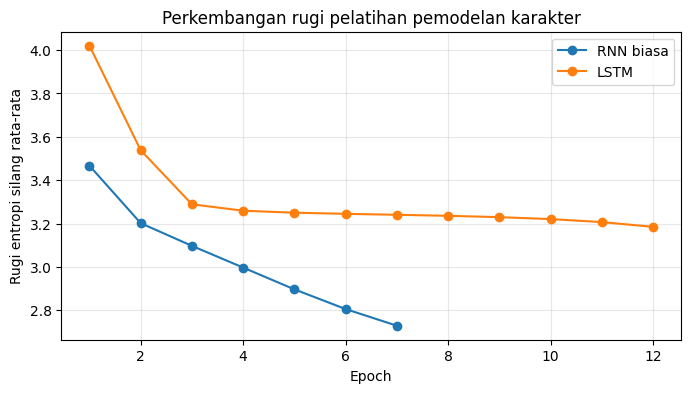

RNN: rugi awal=3.467, rugi akhir=2.729, akurasi akhir=27.62%, perplexity akhir=15.31
LSTM: rugi awal=4.020, rugi akhir=3.185, akurasi akhir=15.16%, perplexity akhir=24.16


In [18]:
plt.figure(figsize=(8,4))
plt.plot([r["epoch"] for r in riwayat_rnn],[r["loss"] for r in riwayat_rnn], marker="o", label="RNN biasa")
plt.plot([r["epoch"] for r in riwayat_lstm],[r["loss"] for r in riwayat_lstm], marker="o", label="LSTM")
plt.title("Perkembangan rugi pelatihan pemodelan karakter")
plt.xlabel("Epoch"); plt.ylabel("Rugi entropi silang rata-rata")
plt.legend(); plt.grid(alpha=.3); plt.show()

for nama, catatan in [("RNN", riwayat_rnn),("LSTM",riwayat_lstm)]:
    print(f"{nama}: rugi awal={catatan[0]['loss']:.3f}, rugi akhir={catatan[-1]['loss']:.3f}, "
          f"akurasi akhir={catatan[-1]['akurasi']:.2%}, perplexity akhir={catatan[-1]['perplexity']:.2f}")

## 14. Menghasilkan karakter baru (*sampling*)

Model mengeluarkan logit untuk semua karakter pada tiap waktu. Kita mengubah logit menjadi probabilitas dengan softmax dan mengambil salah satu karakter secara acak sesuai probabilitasnya. Probabilitas karakter berikutnya dipakai kembali sebagai input dalam bentuk indeks karakter terpilih.

**Temperature** mengubah ketajaman distribusi probabilitas: `T < 1` lebih memilih karakter berpeluang tinggi; `T > 1` lebih beragam tetapi sering kurang masuk akal. Pilihan ini menggunakan *sampling* kategorikal, sebuah variasi yang lebih standar daripada teknik sampling singkat yang ditulis pada bagian contoh buku.

In [19]:
def softmax_stabil(logit, temperature=1.0):
    if temperature <= 0:
        raise ValueError("Temperature harus positif")
    z = np.asarray(logit, dtype=float) / temperature
    z = z - np.max(z)
    p = np.exp(z)
    return p / p.sum()

def hasilkan_teks(embed, model, awalan="ROMEO:\n", jumlah=280, temperature=0.8, seed=123):
    rng = np.random.default_rng(seed)
    hidden = model.init_hidden(1)
    awalan_bersih = ''.join(k for k in awalan if k in char2index)
    if not awalan_bersih:
        awalan_bersih = vocab[0]
    # Memanaskan memori dengan karakter awalan; keluaran terakhir menjadi prediksi karakter berikutnya.
    for karakter in awalan_bersih:
        hidden = putus_riwayat(hidden)
        logit, hidden = model.forward(embed.forward(Tensor([char2index[karakter]])), hidden)
    hasil = [awalan_bersih]
    for _ in range(jumlah):
        peluang = softmax_stabil(logit.data.reshape(-1), temperature)
        indeks_baru = int(rng.choice(len(vocab), p=peluang))
        karakter_baru = index2char[indeks_baru]
        hasil.append(karakter_baru)
        hidden = putus_riwayat(hidden)
        logit, hidden = model.forward(embed.forward(Tensor([indeks_baru])), hidden)
    return ''.join(hasil)

print("Sumber pelatihan:", sumber_aktif)
print("\n--- Sampel RNN biasa ---\n")
print(hasilkan_teks(embed_rnn, model_rnn, awalan="ROMEO:\n", jumlah=260, temperature=0.8, seed=30))
print("\n--- Sampel LSTM ---\n")
print(hasilkan_teks(embed_lstm, model_lstm, awalan="ROMEO:\n", jumlah=260, temperature=0.8, seed=30))

Sumber pelatihan: Unduhan: https://raw.githubusercontent.com/karpathy/char-rnn/master/data/tinyshakespeare/input.txt

--- Sampel RNN biasa ---

ROMEO:
Vf moud moirinerenes paul wpan mhe faev toor cs wouf med thee tys membeat thely the biot iee ohes wesmnsel tuou
Vet

hoaued met ,ou
co neenssnettumare peg tit aer Sid tee pato oMyAe
Teane ,remu
 yesb coo' Iy thall dl :o
fd te a-hevel oes mo Iitt tuns sase
the 

--- Sampel LSTM ---

ROMEO:
:c lrsI eiantbeoiofs m ve tt e egad  Aw stinN uMurtUae f oWehbryueeaieleueschly nd e nhshe f,e.etauasrotgianvit
Lat  it tdcMV u 
tt en
hI'ittrdtuweaii n h spt   se i ao iai ts i yhn c,:efa
tilu  ydpk aoh e y oe ar aob
q
c eo A 
hnyhn i t hr  ltt ruhsen sh son 


### 14.1 Eksperimen: tiga nilai *temperature*

Eksperimen berikut menggunakan model LSTM yang **sama** tetapi mengubah pengacakan saat pemilihan karakter. Secara praktis, sampel teks pendek setelah pelatihan singkat masih mungkin tidak bermakna atau berulang. Untuk kualitas yang menyerupai contoh buku, diperlukan korpus jauh lebih besar, kapasitas model lebih tinggi, dan pelatihan yang jauh lebih lama.

In [20]:
for suhu in [0.6, 1.0, 1.3]:
    print(f"\nTemperature = {suhu}\n" + '-'*26)
    print(hasilkan_teks(embed_lstm, model_lstm, awalan="ROMEO:\n", jumlah=200, temperature=suhu, seed=9))


Temperature = 0.6
--------------------------
ROMEO:
s mootrt
Ca 
rvo oRo swvsshet eier   u aelo to, nh Aomo o 
 seiinao
:  thoihoieef,hdeenl ss rre rr ape
 LheeW,aeenyneu teeser ll r  ese ai e o eeta eeh enet t eogtr elo t  er  nt ietreu ehondtuoco   s

Temperature = 1.0
--------------------------
ROMEO:
tHirotst
de 
syoSnMoIoyyttnht eler  ,v aemr upa,ilN rnr'o 
'phillao
b  tiriirlgiidmemeon rtaose psV,of
 Hiihddehhoyoew vgfsischl.o !Hre
 i d,n eete eei fneudsUbnfut:Iir tb arJ mtaheusew eiroeuyser:  s

Temperature = 1.3
--------------------------
ROMEO:
tIipnusu
de 
sypPnMoJpyyttnhu difr. ,w Nckq upa;ijI'omr:n 
.pgiimao
a ,tiriirlfhicmdleon rtaose osVAof
..hhgadehioyoey wfesisbhlEo' Tre Hi bFn'cetd ech eneuctadngutISlp ta'JrE ktVfcusey:chonduyserG, r
